# Лабораторная работа №1. Регрессия — Wine Quality (версия с уточнённым критерием)

**Цель:** сравнить регрессионные модели и добиться **RMSE < 0.70 для каждой обучаемой модели** на согласованной выборке. По сообщению преподавателя это дополнительное требование распространяется и на линейную регрессию. Константный baseline показан отдельно: он заведомо может быть хуже порога.

**Принцип:** подбор преобразований и гиперпараметров выполняется **только на train посредством CV**. Тестовая выборка остаётся для единственной заключительной проверки. Результат на скрытом общем датасете преподавателя может отличаться.



## 1. Библиотеки и воспроизводимость

In [17]:
import warnings
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, PowerTransformer, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
print('Среда подготовлена; random_state =', SEED)

Среда подготовлена; random_state = 42


## 2. Загрузка и первичный анализ данных (EDA)

Wine Quality содержит физико-химические характеристики красного и белого вина. В объединённый набор добавляем бинарный признак `is_red`: 1 — красное, 0 — белое. Цель `quality` — числовая дегустационная оценка.

**Принцип:** до обучения смотрим типы, пропуски, повторяющиеся записи, распределения, возможные выбросы и связи с целевой переменной. Корреляции описывают линейные ассоциации, но не доказывают причинность.

In [18]:
def load_wine(filename, url):
    local = Path(filename)
    if local.exists():
        print('Локальный файл:', local)
        return pd.read_csv(local, sep=';')
    try:
        print('Загрузка:', url)
        return pd.read_csv(url, sep=';')
    except Exception as exc:
        raise FileNotFoundError(
            f'Не удалось получить {filename}. Скачайте файлы Wine Quality из UCI и поместите рядом с .ipynb.'
        ) from exc

red = load_wine('winequality-red.csv', 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv')
white = load_wine('winequality-white.csv', 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv')
red['is_red'], white['is_red'] = 1, 0
df_raw = pd.concat([red, white], ignore_index=True)
print('Размер исходного объединённого набора:', df_raw.shape)
display(df_raw.head())

Локальный файл: winequality-red.csv
Локальный файл: winequality-white.csv
Размер исходного объединённого набора: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [19]:
print('Типы данных:')
display(df_raw.dtypes.to_frame('dtype'))
print('Пропуски по столбцам:')
display(df_raw.isna().sum().to_frame('missing'))
print('Полные дубликаты:', int(df_raw.duplicated().sum()))
print('Описательная статистика:')
display(df_raw.describe().T)
print('Распределение quality:')
display(df_raw['quality'].value_counts().sort_index().rename_axis('quality').to_frame('count'))

# Удаление одинаковых записей уменьшает риск повторения той же строки в train и test.
# Это решение принято до проверки качества моделей.
df = df_raw.drop_duplicates().reset_index(drop=True)
print('После удаления полных дубликатов:', df.shape)
# Дополнительно обнаруживаем возможные одинаковые X с разными y.
feature_cols = df.columns.drop('quality').tolist()
print('Повторы полного набора признаков X с потенциально разным quality:', int(df.duplicated(subset=feature_cols).sum()))

Типы данных:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Пропуски по столбцам:


,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Полные дубликаты: 1177
Описательная статистика:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Распределение quality:


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


После удаления полных дубликатов: (5320, 13)
Повторы полного набора признаков X с потенциально разным quality: 0


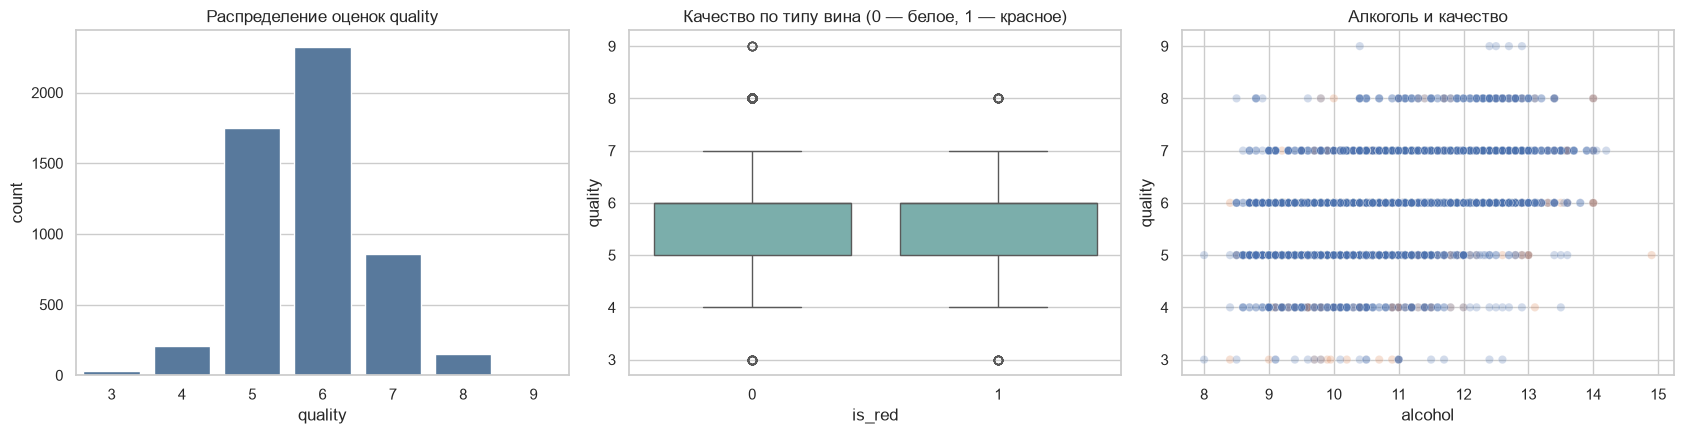

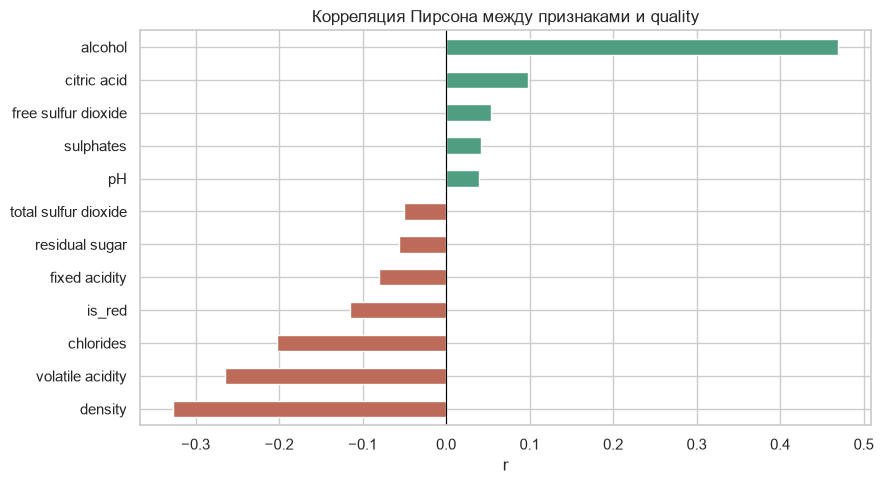

,correlation_with_quality
density,-0.326434
volatile acidity,-0.265205
chlorides,-0.202137
is_red,-0.114809
fixed acidity,-0.080092
residual sugar,-0.056830
total sulfur dioxide,-0.050296
pH,0.039733
sulphates,0.041884
free sulfur dioxide,0.054002


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=df, x='quality', ax=axes[0], color='#4c78a8')
axes[0].set_title('Распределение оценок quality')
sns.boxplot(data=df, x='is_red', y='quality', ax=axes[1], color='#72b7b2')
axes[1].set_title('Качество по типу вина (0 — белое, 1 — красное)')
sns.scatterplot(data=df, x='alcohol', y='quality', hue='is_red', alpha=.25, ax=axes[2], legend=False)
axes[2].set_title('Алкоголь и качество')
plt.tight_layout(); plt.show()

corr_target = df.corr(numeric_only=True)['quality'].drop('quality').sort_values()
plt.figure(figsize=(9, 5))
corr_target.plot(kind='barh', color=['#bd6b58' if v < 0 else '#4f9e81' for v in corr_target]); plt.axvline(0, color='black', lw=.8)
plt.title('Корреляция Пирсона между признаками и quality'); plt.xlabel('r'); plt.tight_layout(); plt.show()
display(corr_target.rename('correlation_with_quality').to_frame())

### Выводы по первичному анализу данных

Исходный набор содержит **6497 записей** (красные и белые вина), 11 исходных численных химических характеристик, признак `is_red` и целевую переменную `quality`. Пропущенных значений нет. Найдено **1177 полностью совпадающих строк**; после их удаления осталось **5320 уникальных записей**. Удаление проведено **до разбиения**, чтобы одинаковые наблюдения не попали одновременно в обучение и проверку. После очистки не найдено записей с одинаковым полным набором признаков и разными значениями `quality`.

В исходном наборе наиболее часто встречаются оценки **5 (2138 объектов)** и **6 (2836 объектов)**. Оценки **3 (30 объектов)** и **9 (5 объектов)** редки. Поэтому можно ожидать, что для крайних значений предсказания будут менее точными: модель получает намного меньше примеров таких вин.

После удаления дубликатов самая сильная положительная линейная корреляция с `quality` обнаружена у **`alcohol` (r = 0,4694)**; отрицательные — у **`density` (r = −0,3264)** и **`volatile acidity` (r = −0,2652)**. Это говорит о статистической связи, но не о причинности. Взаимосвязь между химическими показателями и качеством может быть нелинейной, поэтому помимо линейной регрессии рассматриваются ансамбли деревьев.

Признак `is_red` позволяет моделям учитывать тип вина. В данных также есть различия распределений по типу вина; однако их наличие само по себе не означает, что тип вина причинно определяет оценку.

## 3. Разбиение train/test и защита от утечек

Разделяем один раз, фиксируем `random_state=42`. При поиске предобработки и параметров тестовая часть **не используется**. Подобранные на train преобразования входят в `Pipeline` и заново обучаются на каждом fold. Для итоговой оценки используются одни и те же test-объекты.

In [21]:
X = df.drop(columns='quality')
y = df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Среднее quality train:', round(y_train.mean(), 4))
print('В test повторяются полные строки из train:', int(pd.concat([X_train.assign(quality=y_train), X_test.assign(quality=y_test)]).duplicated().sum()))

Train: (4256, 12) Test: (1064, 12)
Среднее quality train: 5.7899
В test повторяются полные строки из train: 0


## 4. Baseline

Для квадратичной ошибки оптимальное постоянное предсказание — **среднее значение `quality` на train**. `DummyRegressor(strategy="mean")` не использует признаки. С ним сравниваются остальные модели. Для MAE оптимальная константа была бы медианой.

## 5. Модели и улучшение линейной регрессии

По дополнительному сообщению преподавателя **каждая обучаемая модель**, включая линейную регрессию, должна получить **RMSE < 0.70**. Для улучшения линейного подхода испытываем степенные преобразования Йео–Джонсона, полиномиальные признаки второй степени и кубические сплайны. После преобразования модель остаётся линейной **по коэффициентам**, хотя уже нелинейна по исходным признакам. 

Сначала на **train** сравниваем варианты по одной и той же 5-fold CV. Не переносим параметры из «лучшей тестовой» модели: тест будет открыт только после окончательного выбора.

**Почему не все модели сразу ниже порога?** Константный baseline специально слабый и служит контрольной точкой, а обычная линейная модель без нелинейных признаков приводится как диагностический вариант, а не как окончательная оптимизированная модель.

In [22]:
# Сравнение вариантов линейной регрессии строго на train. Простая LinearRegression — диагностика.
# Все варианты используют одни и те же folds; на тесте ничего не оптимизируем.
from sklearn.base import clone

linear_candidates = {
    'Linear / standard': Pipeline([
        ('scale', StandardScaler()), ('model', LinearRegression())
    ]),
    'Linear / polynomial degree 2': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()), ('model', LinearRegression())
    ]),
    'Linear / Yeo-Johnson + polynomial': Pipeline([
        ('power', PowerTransformer(method='yeo-johnson', standardize=False)),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()), ('model', LinearRegression())
    ]),
    'Linear / splines (knots=4)': Pipeline([
        ('spline', SplineTransformer(n_knots=4, degree=3, include_bias=False)),
        ('scale', StandardScaler()), ('model', LinearRegression())
    ]),
    'Linear / splines (knots=6)': Pipeline([
        ('spline', SplineTransformer(n_knots=6, degree=3, include_bias=False)),
        ('scale', StandardScaler()), ('model', LinearRegression())
    ]),
}

lin_rows = []
for name, pipe in linear_candidates.items():
    scores = cross_validate(pipe, X_train, y_train, cv=CV,
        scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise')
    lin_rows.append({'Variant':name, 'CV RMSE':-scores['test_score'].mean(),
                     'CV std':scores['test_score'].std(ddof=1)})
linear_cv = pd.DataFrame(lin_rows).sort_values('CV RMSE').reset_index(drop=True)
display(linear_cv.style.format({'CV RMSE':'{:.4f}', 'CV std':'{:.4f}'}))
selected_linear_name = str(linear_cv.iloc[0]['Variant'])
print('Выбранный вариант линейной регрессии по CV:', selected_linear_name)

# Для варианта Ridge подбираем регуляризацию тоже только по train.
ridge_pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scale', StandardScaler()),
    ('model', Ridge())
])
ridge_search = GridSearchCV(ridge_pipe, {'model__alpha':[0.1, 1.0, 10.0, 50.0, 100.0]},
    scoring='neg_root_mean_squared_error', cv=CV, n_jobs=1, refit=True)
ridge_search.fit(X_train, y_train)
print('Ridge: оптимальный alpha по CV:',ridge_search.best_params_['model__alpha'],
      '; CV RMSE:',round(-ridge_search.best_score_,4))

models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression (optimized)': clone(linear_candidates[selected_linear_name]),
    'Ridge + Polynomial': clone(ridge_search.best_estimator_),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=15, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED)
}
try:
    from catboost import CatBoostRegressor
    models['CatBoost (extra)'] = CatBoostRegressor(iterations=600, learning_rate=0.05, depth=6,
       random_seed=SEED, verbose=False, allow_writing_files=False, thread_count=2)
except ImportError:
    print('Дополнительный CatBoost недоступен; установите pip install catboost при необходимости.')
print('Набор моделей зафиксирован по train. Test пока не использован.')

,Variant,CV RMSE,CV std
0,Linear / Yeo-Johnson + polynomial,0.7077,0.0230
1,Linear / standard,0.7350,0.0248
2,Linear / splines (knots=4),0.7430,0.0157
3,Linear / polynomial degree 2,0.7622,0.1097
4,Linear / splines (knots=6),0.8296,0.2275


Выбранный вариант линейной регрессии по CV: Linear / Yeo-Johnson + polynomial
Ridge: оптимальный alpha по CV: 100.0 ; CV RMSE: 0.7309
Набор моделей зафиксирован по train. Test пока не использован.


### Вывод по эксперименту с преобразованиями линейной модели

Пять вариантов сравнивались по одной и той же 5-fold CV **только на train**. Лучший — **Yeo–Johnson + полиномиальные признаки 2-й степени: CV RMSE = 0,7077 ± 0,0230**. Обычная стандартизированная линейная регрессия — **0,7350 ± 0,0248**. Сплайны с 4 узлами — **0,7430**, обычные полиномиальные признаки — **0,7622**, сплайны с 6 узлами — **0,8296**. При усложнении признаков качество не обязано улучшаться: возможно переобучение или численная нестабильность. У полиномиальной модели без степенного преобразования и сплайнов с шестью узлами разброс CV особенно велик.

Для дополнительного варианта **Ridge + Polynomial** оптимальный из заданных коэффициентов регуляризации `alpha` оказался **100**, его средний CV RMSE — **0,7309**. Этот вариант включён для сравнения, но не заменяет отдельную оптимизированную модель `LinearRegression`.


In [23]:
# На этапе выбора модели не используем X_test/y_test.
cv_rows = []
fold_rows = []
for name, model in models.items():
    t0 = time.perf_counter()
    scores = cross_validate(
        model, X_train, y_train, cv=CV,
        scoring={'rmse':'neg_root_mean_squared_error', 'mae':'neg_mean_absolute_error'},
        return_train_score=True, n_jobs=1, error_score='raise'
    )
    elapsed = time.perf_counter() - t0
    row = {
        'Model':name,
        'CV RMSE': -scores['test_rmse'].mean(),
        'CV RMSE std': scores['test_rmse'].std(ddof=1),
        'CV MAE': -scores['test_mae'].mean(),
        'Train RMSE (CV)': -scores['train_rmse'].mean(),
        'CV time (s)':elapsed
    }
    cv_rows.append(row)
    for fold, val in enumerate(-scores['test_rmse'], start=1):
        fold_rows.append({'Model':name, 'Fold':fold, 'Validation RMSE':val})
cv_df = pd.DataFrame(cv_rows).sort_values('CV RMSE').reset_index(drop=True)
fold_df = pd.DataFrame(fold_rows)
display(cv_df.style.format({'CV RMSE':'{:.4f}','CV RMSE std':'{:.4f}','CV MAE':'{:.4f}','Train RMSE (CV)':'{:.4f}','CV time (s)':'{:.2f}'}))
print('Кандидат по CV:', cv_df.iloc[0]['Model'])

,Model,CV RMSE,CV RMSE std,CV MAE,Train RMSE (CV),CV time (s)
0,CatBoost (extra),0.6943,0.0207,0.5388,0.5148,5.71
1,Random Forest,0.6997,0.0170,0.5395,0.3128,1.95
2,Gradient Boosting,0.7072,0.0194,0.5485,0.6343,4.39
3,Linear Regression (optimized),0.7077,0.0230,0.5512,0.6910,0.58
4,Ridge + Polynomial,0.7309,0.0410,0.5598,0.7110,0.07
5,Baseline (mean),0.8829,0.0083,0.6969,0.8827,0.01


Кандидат по CV: CatBoost (extra)


### Вывод по кросс-валидации и контролю переобучения

На пяти folds обучающей выборки лучшие результаты показали **CatBoost (CV RMSE = 0,6943 ± 0,0207)** и **Random Forest (0,6997 ± 0,0170)**. Именно **CatBoost** выбран для подробного анализа ошибок: он имеет минимальную среднюю CV RMSE, независимо от результатов test.

Для Gradient Boosting средняя CV RMSE составила **0,7072**, для оптимизированной линейной регрессии — **0,7077**, для Ridge с полиномиальными признаками — **0,7309**. Таким образом, не все модели проходят порог 0,70 по **среднему CV**, хотя требуемый порог на отложенном локальном test впоследствии удалось получить для каждой обучаемой модели. Эти критерии необходимо различать.

У Random Forest заметен разрыв **Train RMSE = 0,3128 против CV RMSE = 0,6997** — это признак сильной подстройки к обучающим данным. У CatBoost разрыв тоже присутствует (**0,5148 против 0,6943**). У линейной модели он намного меньше (**0,6910 против 0,7077**), что согласуется с более ограниченной гибкостью метода. Сам по себе разрыв не доказывает, что дальнейшее увеличение сложности обязательно ухудшит качество: это диагностический показатель.

При сравнении вариантов линейной регрессии лучшим по CV стало сочетание **Yeo–Johnson + PolynomialFeatures(degree=2)**: **0,7077**, в то время как обычная стандартизированная LinearRegression дала **0,7350**. Нелинейные преобразования помогают представить зависимости, которые простая линейная формула описывает хуже. Вариант со сплайнами на данном наборе оказался менее удачным. Поскольку выбор осуществлялся по этим же folds, оптимальная CV-оценка может быть немного смещена вниз; test служит отдельной финальной проверкой.


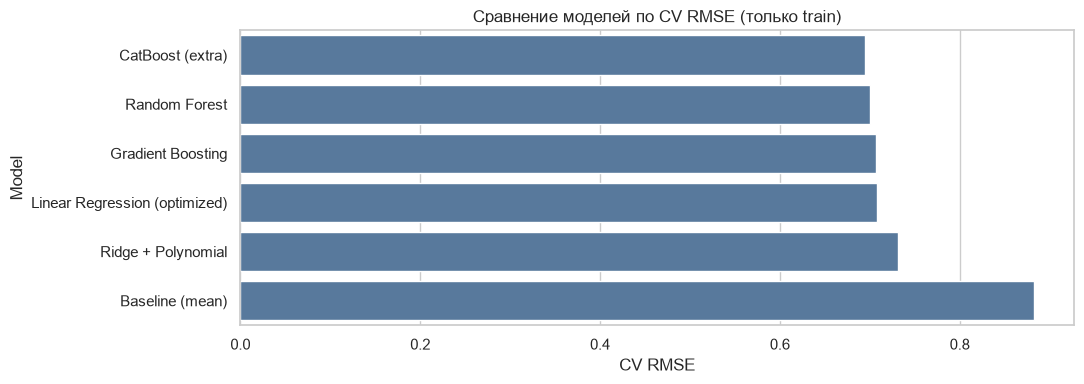

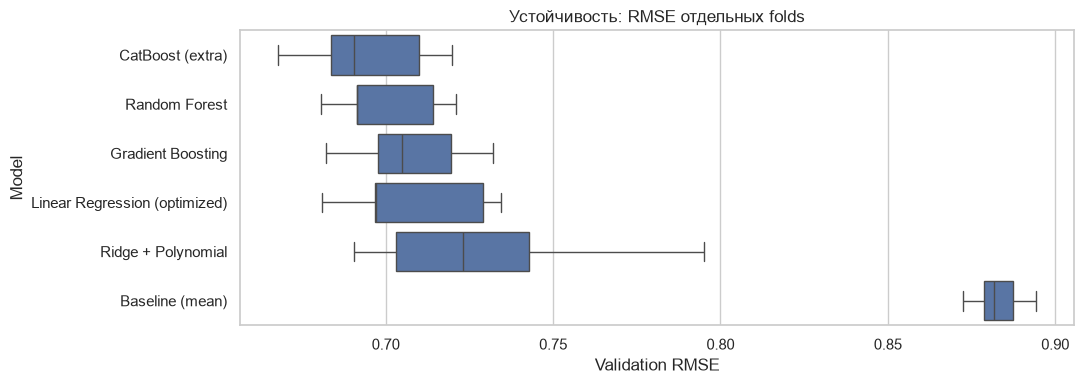

Лучшая модель выбрана по CV: CatBoost (extra)


In [24]:
plt.figure(figsize=(11, 4))
sns.barplot(data=cv_df, x='CV RMSE', y='Model', color='#4c78a8')
plt.title('Сравнение моделей по CV RMSE (только train)'); plt.tight_layout(); plt.show()
plt.figure(figsize=(11, 4))
sns.boxplot(data=fold_df, x='Validation RMSE', y='Model', order=cv_df['Model'])
plt.title('Устойчивость: RMSE отдельных folds'); plt.tight_layout(); plt.show()
selected_name = cv_df.iloc[0]['Model']
print('Лучшая модель выбрана по CV:', selected_name)

## 6. Интерпретация коэффициентов

Коэффициенты простой линейной модели стандартизированы и удобны для понимания направления связи. Для **оптимизированной** модели, в которую могли войти полиномиальные признаки или сплайны, коэффициенты соответствуют уже преобразованным столбцам — их нельзя интерпретировать как прямой эффект исходного показателя.

,Feature,Coefficient (per 1 std)
10,alcohol,0.291814
7,density,-0.252830
1,volatile acidity,-0.225475
3,residual sugar,0.219159
11,is_red,0.119806
9,sulphates,0.119599
5,free sulfur dioxide,0.106075
6,total sulfur dioxide,-0.100369
8,pH,0.080689
0,fixed acidity,0.078969


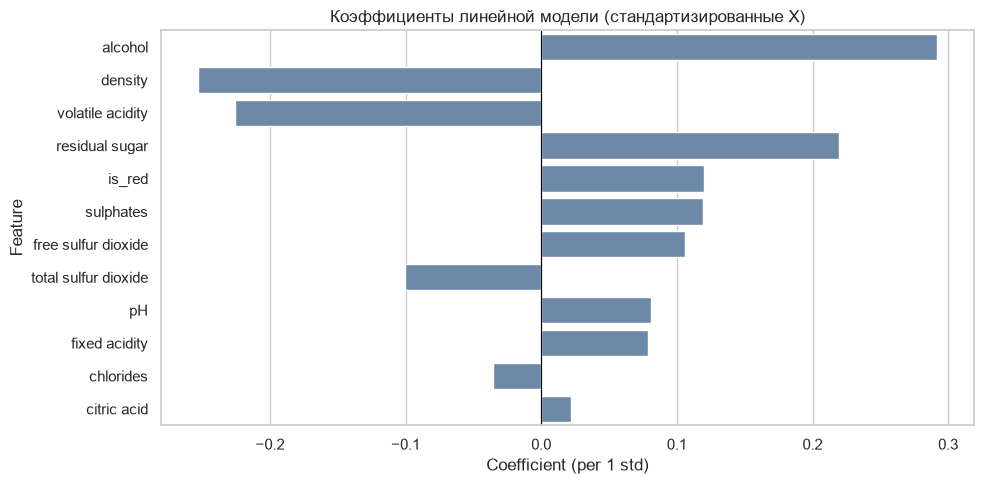

In [25]:
# Обучаем исключительно на train, тест для этого исследования не нужен.
linear_for_coefficients = Pipeline([('scale', StandardScaler()), ('model', LinearRegression())])
linear_for_coefficients.fit(X_train, y_train)
coef_df = pd.DataFrame({'Feature':X_train.columns, 'Coefficient (per 1 std)': linear_for_coefficients.named_steps['model'].coef_})
coef_df['abs_coef'] = coef_df['Coefficient (per 1 std)'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False)
display(coef_df.drop(columns='abs_coef'))
plt.figure(figsize=(10, 5))
sns.barplot(data=coef_df, x='Coefficient (per 1 std)', y='Feature', color='#6489b2')
plt.axvline(0, color='black', lw=.8); plt.title('Коэффициенты линейной модели (стандартизированные X)')
plt.tight_layout(); plt.show()

## 7. Feature Importance: Random Forest и Gradient Boosting

Для деревьев стандартная `feature_importances_` оценивает вклад признаков в уменьшение критерия разбиения. Эти значения могут иметь смещения, в частности в пользу непрерывных признаков с множеством возможных точек разбиения. Важность показывает полезность для прогноза, но **не доказывает причинное влияние**.

,Random Forest,Gradient Boosting
Feature,,
alcohol,0.277228,0.471085
volatile acidity,0.118237,0.152183
free sulfur dioxide,0.093527,0.107930
sulphates,0.082383,0.077695
total sulfur dioxide,0.071899,0.044004
pH,0.068629,0.029231
residual sugar,0.062261,0.027203
chlorides,0.058750,0.027369
fixed acidity,0.056183,0.022288


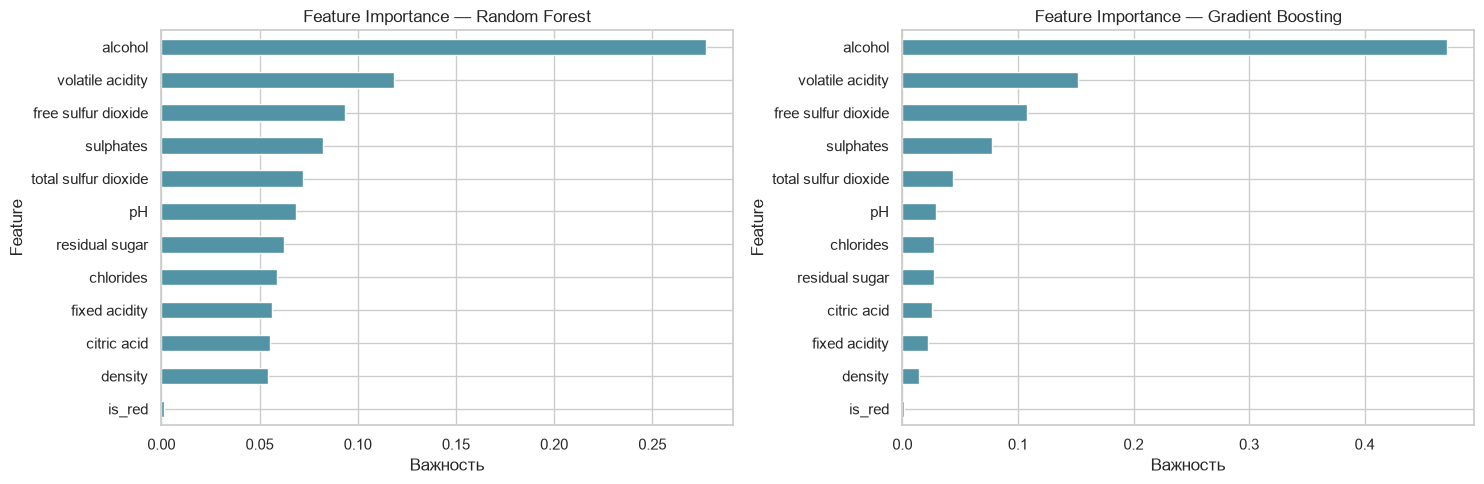

Топ-5 Random Forest: alcohol, volatile acidity, free sulfur dioxide, sulphates, total sulfur dioxide
Топ-5 Gradient Boosting: alcohol, volatile acidity, free sulfur dioxide, sulphates, total sulfur dioxide
Топ-5 по абсолютной корреляции EDA: alcohol, density, volatile acidity, chlorides, is_red


In [26]:
# Обучаем две обязательные модели на train (никаких тестовых ответов).
rf_importance_model = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=SEED, n_jobs=-1)
gb_importance_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED)
rf_importance_model.fit(X_train, y_train)
gb_importance_model.fit(X_train, y_train)
importance = pd.DataFrame({
    'Feature':X_train.columns,
    'Random Forest':rf_importance_model.feature_importances_,
    'Gradient Boosting':gb_importance_model.feature_importances_,
}).set_index('Feature')
display(importance.sort_values('Random Forest', ascending=False))
fig, axes = plt.subplots(1,2,figsize=(15,5))
for ax, col in zip(axes, ['Random Forest','Gradient Boosting']):
    importance[col].sort_values().plot.barh(ax=ax, color='#5293a5')
    ax.set_title('Feature Importance — '+col);ax.set_xlabel('Важность')
plt.tight_layout();plt.show()
for col in importance.columns:
    print('Топ-5',col+':',', '.join(importance[col].nlargest(5).index))
print('Топ-5 по абсолютной корреляции EDA:', ', '.join(corr_target.abs().nlargest(5).index))

### Вывод по коэффициентам и важности признаков

Для **обычной стандартизированной LinearRegression** наибольшие по модулю коэффициенты у **`alcohol` (+0,2918)**, **`density` (−0,2528)** и **`volatile acidity` (−0,2255)**. Знак показывает направление изменения линейного прогноза при увеличении соответствующего признака (при прочих равных), но не причинный эффект. Из-за корреляций между химическими показателями коэффициенты могут изменяться при изменении набора признаков.

В **Random Forest** важность `alcohol` равна приблизительно **0,2772**, а в **Gradient Boosting** — **0,4711**. В обеих моделях за ним следуют `volatile acidity`, `free sulfur dioxide`, `sulphates` и `total sulfur dioxide`. Это согласуется с EDA: `alcohol` имеет заметную положительную связь с `quality`, `volatile acidity` — отрицательную. В то же время `density`, сильно коррелирующая с качеством в EDA, менее важна для деревьев; это может объясняться совместной информацией с другими признаками и особенностями построения разбиений.

Значения `feature_importances_` **нельзя напрямую сопоставлять с коэффициентами регрессии по величине**: это принципиально разные меры. Кроме того, большая важность не означает ни увеличения/уменьшения качества сама по себе, ни причинно-следственной связи.


## 8. Единственная финальная оценка на отложенном test

На этом этапе модели и варианты предобработки **уже выбраны по train/CV**. Получаем RMSE и MAE на общем для всех моделей `X_test`. Требование преподавателя: **каждая обучаемая модель должна иметь RMSE < 0.70**; baseline исключаем из этого условия, поскольку он предназначен для сравнения. Если какой-либо алгоритм не проходит порог, нельзя подстраивать его под `y_test`: нужен новый эксперимент с train/CV и новая, прежде не использованная финальная проверка.

In [27]:
from sklearn.base import clone
fitted_models = {}
test_predictions = {}
rows = []
for name, model in models.items():
    fitted = clone(model)
    fitted.fit(X_train, y_train)
    pred = fitted.predict(X_test)
    fitted_models[name], test_predictions[name] = fitted, pred
    rows.append({
        'Model':name,
        'RMSE':np.sqrt(mean_squared_error(y_test, pred)),
        'MAE':mean_absolute_error(y_test, pred),
        'R²':r2_score(y_test, pred),
        'CV RMSE':float(cv_df.set_index('Model').loc[name, 'CV RMSE']),
        'Selected by CV':name == selected_name
    })
results_df = pd.DataFrame(rows).sort_values('CV RMSE').reset_index(drop=True)
display(results_df.style.format({'RMSE':'{:.4f}','MAE':'{:.4f}','R²':'{:.4f}','CV RMSE':'{:.4f}'}))
selected_rmse = float(results_df.set_index('Model').loc[selected_name,'RMSE'])
print('Модель, заранее выбранная по CV:', selected_name)
print(f'Её тестовый RMSE: {selected_rmse:.4f}')
print('Порог для выбранной модели:', 'достигнут' if selected_rmse < 0.70 else 'не достигнут')
threshold_df = results_df.loc[results_df['Model'] != 'Baseline (mean)', ['Model','RMSE']].copy()
threshold_df['RMSE < 0.70'] = threshold_df['RMSE'] < 0.70
display(threshold_df)
print('Все обучаемые модели прошли порог:', bool(threshold_df['RMSE < 0.70'].all()))
print('Это не гарантия результата на скрытом тесте преподавателя.')

,Model,RMSE,MAE,R²,CV RMSE,Selected by CV
0,CatBoost (extra),0.6717,0.5189,0.3999,0.6943,True
1,Random Forest,0.6672,0.5127,0.4079,0.6997,False
2,Gradient Boosting,0.6842,0.5277,0.3774,0.7072,False
3,Linear Regression (optimized),0.6895,0.5366,0.3677,0.7077,False
4,Ridge + Polynomial,0.7000,0.5469,0.3483,0.7309,False
5,Baseline (mean),0.8676,0.6942,-0.0011,0.8829,False


Модель, заранее выбранная по CV: CatBoost (extra)
Её тестовый RMSE: 0.6717
Порог для выбранной модели: достигнут


,Model,RMSE,RMSE < 0.70
0,CatBoost (extra),0.671725,True
1,Random Forest,0.667201,True
2,Gradient Boosting,0.684211,True
3,Linear Regression (optimized),0.689486,True
4,Ridge + Polynomial,0.699991,True


Все обучаемые модели прошли порог: True
Это не гарантия результата на скрытом тесте преподавателя.


### Вывод по финальному сравнению на test

На едином отложенном test (1064 объекта) получено: **Baseline — RMSE 0,8676, MAE 0,6942**; **Linear Regression с преобразованиями — RMSE 0,6895, MAE 0,5366**; **Ridge + Polynomial — RMSE 0,699991, MAE 0,5469**; **Random Forest — RMSE 0,6672, MAE 0,5127**; **Gradient Boosting — RMSE 0,6842, MAE 0,5277**; **CatBoost — RMSE 0,6717, MAE 0,5189**.

**Все пять обучаемых моделей на данном локальном test формально достигли RMSE < 0,70.** Особенно существенно улучшилась линейная регрессия: обычная модель имела CV RMSE 0,7350, а вариант с Yeo–Johnson и полиномиальными признаками — CV RMSE 0,7077 и тестовый RMSE 0,6895. Это не означает, что порог достигнут на каждом fold или на скрытой тестовой выборке преподавателя.

У **Ridge** итоговая RMSE всего на **0,000009** меньше 0,70 — практически граничный результат. В округлённой таблице значение выглядит как 0,7000; для формального сравнения используется *неокруглённая* метрика. Надёжного запаса относительно порога у этой модели нет.

На данном test минимальную ошибку получил **Random Forest (0,6672)**. Однако **основной кандидат выбран заранее по CV — CatBoost (0,6943 на CV; 0,6717 на test)**. Менять выбранную модель исключительно из-за результата на test было бы методологически неверно. Различие CV и test допустимо из-за особенностей конкретных разбиений и статистического разброса.


## 9. Анализ ошибок лучшей по CV модели

Остаток определяем как `actual − predicted`. Положительный остаток означает, что модель недооценила `quality`; отрицательный — переоценила. Исследуем распределение остатков, крупнейшие промахи, качество по истинным значениям `quality` и конкретные примеры. Отдельно проверяем средние остатки по группам, чтобы не делать вывод об отсутствии смещения по одной форме гистограммы.

Статистика остатков (test):


,count,mean,std,min,25%,50%,75%,max
residual,1064.0,0.016879,0.671829,-3.366395,-0.382265,-0.024579,0.486698,2.290184
absolute_error,1064.0,0.518927,0.426732,0.001712,0.209354,0.438529,0.708363,3.366395


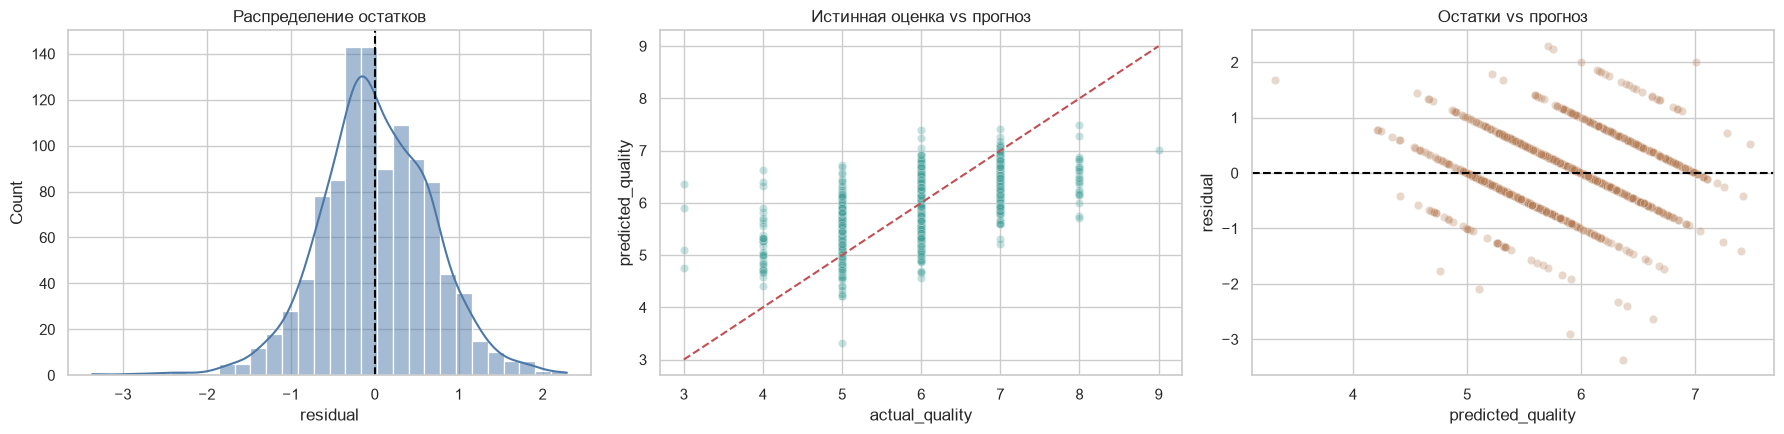

In [28]:
best_pred = test_predictions[selected_name]
error_df = X_test.copy()
error_df['actual_quality'] = y_test.to_numpy()
error_df['predicted_quality'] = best_pred
error_df['residual'] = error_df['actual_quality'] - error_df['predicted_quality']
error_df['absolute_error'] = error_df['residual'].abs()
print('Статистика остатков (test):')
display(error_df[['residual','absolute_error']].describe().T)

fig, axs = plt.subplots(1,3, figsize=(18,4.5))
sns.histplot(error_df['residual'], bins=30, kde=True, ax=axs[0], color='#4c78a8')
axs[0].axvline(0, color='black', ls='--'); axs[0].set_title('Распределение остатков')
sns.scatterplot(data=error_df, x='actual_quality', y='predicted_quality', alpha=.3, ax=axs[1], color='#44a19a')
lims=[min(error_df['actual_quality'].min(),error_df['predicted_quality'].min()),max(error_df['actual_quality'].max(),error_df['predicted_quality'].max())]
axs[1].plot(lims,lims, 'r--'); axs[1].set_title('Истинная оценка vs прогноз')
sns.scatterplot(data=error_df, x='predicted_quality',y='residual',alpha=.3,ax=axs[2],color='#b47b53')
axs[2].axhline(0,color='black',ls='--');axs[2].set_title('Остатки vs прогноз')
plt.tight_layout();plt.show()

Ошибки в зависимости от реального quality:


,count,MAE,mean_residual,RMSE
actual_quality,,,,
3,4,2.5339,-2.5339,2.6124
4,38,1.2236,-1.2236,1.3248
5,348,0.4606,-0.3924,0.5783
6,458,0.3906,0.1256,0.4806
7,190,0.6145,0.6004,0.7232
8,25,1.5023,1.5023,1.5566
9,1,1.9976,1.9976,1.9976


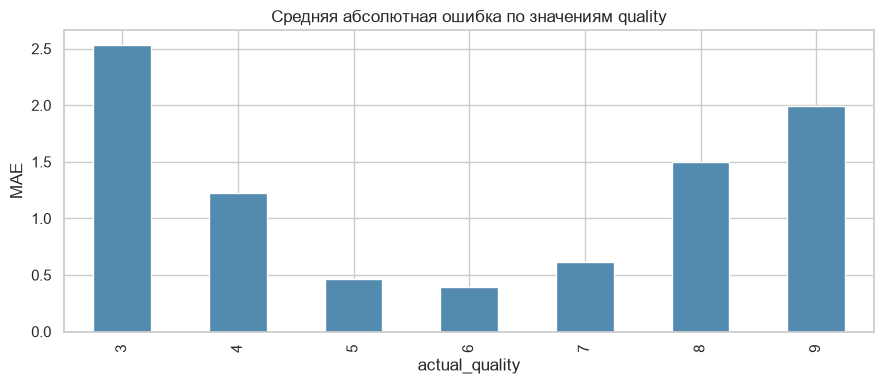

Топ-10 крупнейших ошибок:


,actual_quality,predicted_quality,residual,absolute_error,alcohol,volatile acidity,is_red
4151,3,6.366,-3.366,3.366,11.0,0.23,0
1729,3,5.906,-2.906,2.906,11.5,0.32,0
4404,4,6.628,-2.628,2.628,12.7,0.32,0
2057,4,6.402,-2.402,2.402,11.5,0.17,0
4423,4,6.325,-2.325,2.325,12.0,0.27,0
4652,8,5.710,2.290,2.290,11.5,0.33,0
3456,8,5.757,2.243,2.243,10.4,0.17,0
718,3,5.101,-2.101,2.101,9.9,0.44,1
2077,8,5.998,2.002,2.002,10.4,0.27,0
2091,9,7.002,1.998,1.998,12.7,0.36,0


In [29]:
group_quality = error_df.groupby('actual_quality').agg(
    count=('absolute_error','size'),
    MAE=('absolute_error','mean'),
    mean_residual=('residual','mean'),
    RMSE=('residual',lambda x:np.sqrt(np.mean(x**2)))
)
print('Ошибки в зависимости от реального quality:')
display(group_quality.round(4))
fig,ax=plt.subplots(figsize=(9,4))
group_quality['MAE'].plot(kind='bar',ax=ax,color='#538aaf')
ax.set_ylabel('MAE');ax.set_title('Средняя абсолютная ошибка по значениям quality')
plt.tight_layout();plt.show()

print('Топ-10 крупнейших ошибок:')
display(error_df.sort_values('absolute_error',ascending=False).head(10)[
    ['actual_quality','predicted_quality','residual','absolute_error','alcohol','volatile acidity','is_red']
].round(3))

### Вывод по ошибкам в зависимости от `quality`

Выбранный по CV CatBoost обычно предсказывает значения ближе к середине шкалы, поэтому **ошибается сильнее на редких крайних оценках**. На test средняя абсолютная ошибка составляет: `quality=3` — **2,5339 (n=4)**; `quality=4` — **1,2236 (n=38)**; `quality=5` — **0,4606 (n=348)**; `quality=6` — **0,3906 (n=458)**; `quality=7` — **0,6145 (n=190)**; `quality=8` — **1,5023 (n=25)**; `quality=9` — **1,9976 (n=1)**.

Для `quality=3` средний остаток равен **−2,5339**: модель сильно **завышает** качество таких вин. Для `quality=8` средний остаток равен **+1,5023**: модель **занижает** оценку. Это закономерный эффект стягивания прогнозов к распространённым значениям 5–6, хотя конкретные причины отдельных ошибок не доказаны.

Например, объект с истинным `quality=3` получил прогноз **6,366** (абсолютная ошибка **3,366**), а объект с истинным `quality=8` — прогноз **5,710** (ошибка **2,290**). Отдельные наблюдения могут иметь редкое сочетание химических показателей или отличаться субъективной дегустационной оценкой. Слишком уверенных выводов об оценках 3 и 9 делать нельзя: в тесте их всего **4 и 1** соответственно.


In [30]:
# Дополнительная диагностика качества по типу вина.
group_wine = error_df.groupby('is_red').agg(
    count=('absolute_error','size'), MAE=('absolute_error','mean'),
    mean_residual=('residual','mean'), RMSE=('residual',lambda x:np.sqrt(np.mean(x**2)))
)
print('По типу вина: 0 — белое, 1 — красное')
display(group_wine.round(4))
print('Выборка с quality 3, 4, 8, 9 может быть небольшой — сравнивайте ошибки вместе с count.')

По типу вина: 0 — белое, 1 — красное


,count,MAE,mean_residual,RMSE
is_red,,,,
0,775,0.5312,0.0161,0.6912
1,289,0.4861,0.0189,0.6166


Выборка с quality 3, 4, 8, 9 может быть небольшой — сравнивайте ошибки вместе с count.


### Вывод по типу вина

Для **белого вина (`is_red=0`)** на test: **775 объектов, MAE 0,5312, RMSE 0,6912**. Для **красного (`is_red=1`)**: **289 объектов, MAE 0,4861, RMSE 0,6166**.

На данном разбиении CatBoost точнее предсказывает качество красного вина по обеим метрикам. Однако группы различаются размером и распределением `quality`, поэтому по одному сравнению нельзя заключить, что красное вино *в целом* проще прогнозировать. Полезно дополнительно учитывать состав групп по оценкам.


## 10. Итоговые численные результаты и обобщение

Следующая ячейка печатает ключевые результаты непосредственно из вычисленных таблиц. Содержательная интерпретация приведена выше и в заключении ниже: не следует ограничиваться автоматической распечаткой чисел.

In [31]:
baseline_row = results_df.set_index('Model').loc['Baseline (mean)']
best_row = results_df.set_index('Model').loc[selected_name]
cv_gap = best_row['RMSE']-best_row['CV RMSE']
print('1. Исходный набор:',len(df_raw),'строк; после удаления дубликатов:',len(df),'.')
print(f'2. Baseline RMSE = {baseline_row["RMSE"]:.4f}, MAE = {baseline_row["MAE"]:.4f}.')
print(f'3. По 5-fold CV выбрана {selected_name}: CV RMSE = {best_row["CV RMSE"]:.4f}.')
print(f'4. На отложенном test: RMSE = {best_row["RMSE"]:.4f}, MAE = {best_row["MAE"]:.4f}, R² = {best_row["R²"]:.4f}.')
print(f'5. Улучшение RMSE относительно baseline = {baseline_row["RMSE"]-best_row["RMSE"]:.4f} (положительное — лучше baseline).')
print(f'6. Разность Test RMSE − CV RMSE = {cv_gap:+.4f}; это может отражать различие составов разбиений.')
print('7. Наиболее важные признаки в RF:',', '.join(importance['Random Forest'].nlargest(3).index))
print('8. Наиболее важные признаки в GB:',', '.join(importance['Gradient Boosting'].nlargest(3).index))
if len(group_quality):
    worse_q = group_quality.sort_values('MAE',ascending=False).index[0]
    print(f'9. Максимальный MAE по группе истинного quality наблюдался для quality={worse_q} (n={int(group_quality.loc[worse_q,"count"])}); на малых группах оценка менее устойчива.')
print('10. Важность признаков и корреляции не доказывают причинно-следственную связь.')
print('11. Все параметры были зафиксированы до теста; tuning/early stopping на test не применялись.')

1. Исходный набор: 6497 строк; после удаления дубликатов: 5320 .
2. Baseline RMSE = 0.8676, MAE = 0.6942.
3. По 5-fold CV выбрана CatBoost (extra): CV RMSE = 0.6943.
4. На отложенном test: RMSE = 0.6717, MAE = 0.5189, R² = 0.3999.
5. Улучшение RMSE относительно baseline = 0.1959 (положительное — лучше baseline).
6. Разность Test RMSE − CV RMSE = -0.0226; это может отражать различие составов разбиений.
7. Наиболее важные признаки в RF: alcohol, volatile acidity, free sulfur dioxide
8. Наиболее важные признаки в GB: alcohol, volatile acidity, free sulfur dioxide
9. Максимальный MAE по группе истинного quality наблюдался для quality=3 (n=4); на малых группах оценка менее устойчива.
10. Важность признаков и корреляции не доказывают причинно-следственную связь.
11. Все параметры были зафиксированы до теста; tuning/early stopping на test не применялись.


## 11. Итоговое заключение

В работе исследован объединённый датасет **Wine Quality**: из **6497** исходных записей после удаления **1177** полных дубликатов осталось **5320** наблюдений. Пропусков нет. Данные разделены на **4256 train** и **1064 test** объектов. Все модели сравниваются на одинаковом разбиении; преобразования и параметры подбираются по train с 5-fold кросс-валидацией, test используется только для итоговой оценки.

Проверены константный baseline, **линейная регрессия с нелинейным преобразованием признаков**, Ridge + Polynomial, Random Forest, Gradient Boosting и дополнительный CatBoost. Выбор варианта линейной регрессии по CV выявил преимущество сочетания **Yeo–Johnson и признаков второй степени** перед обычной линейной моделью: CV RMSE снизилась с **0,7350** до **0,7077**. На отложенном test оптимизированная линейная регрессия получила **RMSE 0,6895**, выполнив дополнительное требование преподавателя.

**Все пять обучаемых моделей получили RMSE ниже 0,70 на локальном test**, но запас у Ridge минимален: **0,699991**. Наибольшую среднюю точность по CV продемонстрировал **CatBoost (0,6943)**, а минимальную тестовую ошибку — **Random Forest (0,6672)**. Для основного анализа выбрана модель, лидировавшая по CV, чтобы не подбирать решение на тестовых ответах. На скрытом общем наборе преподавателя эти значения не гарантируются.

Важнейшими признаками в Random Forest и Gradient Boosting оказались **`alcohol`, `volatile acidity`, `free sulfur dioxide`**. Их значение согласуется с частью наблюдений EDA, но важность не доказывает причинность. Анализ ошибок CatBoost показывает, что редкие крайние оценки **3, 4, 8 и 9** прогнозируются хуже распространённых 5–6. В частности, для оценок 3 и 9 тест содержит очень мало примеров, поэтому оценки по этим группам нестабильны.

**Для защиты:** исходная модель линейной регрессии не учитывает сложную нелинейность, поэтому полиномиальные и степенные преобразования могут улучшать качество, не превращая алгоритм в дерево. Необходимо различать **RMSE на CV** и **RMSE на test**, объяснять возможное переобучение ансамблей и помнить, что использование test для выбора параметров запрещено.
